In [1]:
%pip install -q pandas numpy scikit-learn matplotlib joblib transformers datasets accelerate torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss, classification_report, roc_auc_score
import joblib

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA_PATH = "dataset/train.csv"
TEXT_COL = "comment_text"
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

In [5]:
df = pd.read_csv(DATA_PATH)
df = df[[TEXT_COL] + LABELS].copy()
df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
df[LABELS] = df[LABELS].fillna(0).astype(int)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (159571, 7)


,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [7]:
display(df[LABELS].sum().sort_values(ascending=False).to_frame("positive_count"))

,positive_count
toxic,15294
obscene,8449
insult,7877
severe_toxic,1595
identity_hate,1405
threat,478


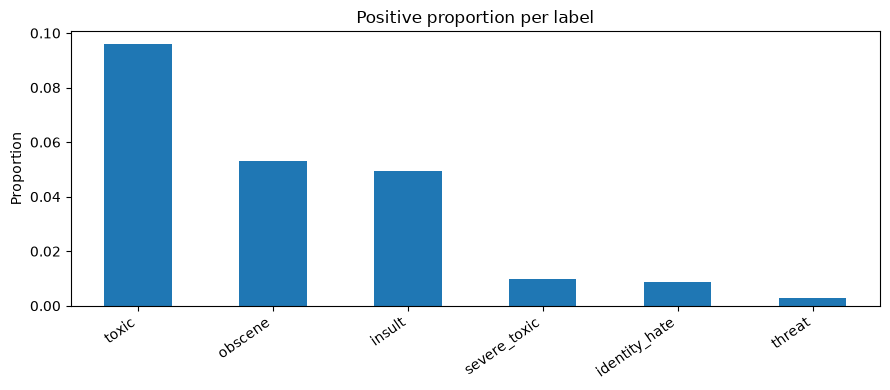

In [8]:
df[LABELS].mean().sort_values(ascending=False).plot(kind="bar", figsize=(9,4))
plt.title("Positive proportion per label")
plt.ylabel("Proportion")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [9]:
train_df, temp_df = train_test_split(df, test_size=0.20, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED)
X_train, y_train = train_df[TEXT_COL].tolist(), train_df[LABELS].values
X_val, y_val = val_df[TEXT_COL].tolist(), val_df[LABELS].values
X_test, y_test = test_df[TEXT_COL].tolist(), test_df[LABELS].values
print("Train / validation / test:", len(train_df), len(val_df), len(test_df))

Train / validation / test: 127656 15957 15958


In [10]:
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=150_000, ngram_range=(1,2), min_df=2, sublinear_tf=True)),
    ("classifier", OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight="balanced", solver="liblinear")))
])
baseline.fit(X_train, y_train)
baseline_val_probs = baseline.predict_proba(X_val)
baseline_test_probs = baseline.predict_proba(X_test)
print("training complete.")

training complete.


In [11]:
def evaluate_multilabel(y_true, probabilities, label_names=LABELS, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    print("Macro F1:", round(f1_score(y_true, predictions, average="macro", zero_division=0), 4))
    print("Micro F1:", round(f1_score(y_true, predictions, average="micro", zero_division=0), 4))
    print("Macro precision:", round(precision_score(y_true, predictions, average="macro", zero_division=0), 4))
    print("Macro recall:", round(recall_score(y_true, predictions, average="macro", zero_division=0), 4))
    print("Hamming loss:", round(hamming_loss(y_true, predictions), 4))
    print(classification_report(y_true, predictions, target_names=label_names, zero_division=0))
    try: print("Macro ROC-AUC:", round(roc_auc_score(y_true, probabilities, average="macro"), 4))
    except ValueError as e: print("ROC-AUC unavailable:", e)
    return predictions

baseline_test_pred = evaluate_multilabel(y_test, baseline_test_probs)

Macro F1: 0.5921
Micro F1: 0.7025
Macro precision: 0.4871
Macro recall: 0.807
Hamming loss: 0.0263
               precision    recall  f1-score   support

        toxic       0.67      0.85      0.75      1520
 severe_toxic       0.30      0.81      0.44       162
      obscene       0.73      0.86      0.79       856
       threat       0.35      0.78      0.48        37
       insult       0.61      0.85      0.71       808
identity_hate       0.26      0.68      0.38       138

    micro avg       0.60      0.85      0.70      3521
    macro avg       0.49      0.81      0.59      3521
 weighted avg       0.63      0.85      0.72      3521
  samples avg       0.06      0.08      0.07      3521

Macro ROC-AUC: 0.9826


In [12]:
def moderate_baseline(text, threshold=0.5):
    probs = baseline.predict_proba([str(text)])[0]
    scores = {label: float(score) for label, score in zip(LABELS, probs)}
    categories = [label for label, score in scores.items() if score >= threshold]
    offensive_like = any(scores[x] >= threshold for x in ["toxic", "obscene", "insult"])
    return {"text": str(text), "categories": categories or ["none above threshold"],
            "offensive_like": bool(offensive_like), "scores": scores}

example = "I disagree with your argument."
result = moderate_baseline(example)
print(result)
display(pd.DataFrame({"category": LABELS, "score": list(result["scores"].values())}).sort_values("score", ascending=False))

{'text': 'I disagree with your argument.', 'categories': ['none above threshold'], 'offensive_like': False, 'scores': {'toxic': 0.34138993671493506, 'severe_toxic': 0.03972468882187701, 'obscene': 0.07879148056104357, 'threat': 0.014696795688519742, 'insult': 0.2075864762227153, 'identity_hate': 0.02463802460560642}}


,category,score
0,toxic,0.341390
4,insult,0.207586
2,obscene,0.078791
1,severe_toxic,0.039725
5,identity_hate,0.024638
3,threat,0.014697


In [13]:
OFFENSIVE_WORDS = ["idiot", "stupid", "moron"]

def mask_offensive_terms(text, terms=OFFENSIVE_WORDS):
    masked = str(text)
    for term in sorted(set(terms), key=len, reverse=True):
        if term.strip():
            pattern = re.compile(rf"(?i)\b{re.escape(term)}\b")
            masked = pattern.sub(lambda m: "*" * len(m.group(0)), masked)
    return masked

sample = "You are an idiot. That was a stupid idea."
print("Original:", sample)
print("Masked:  ", mask_offensive_terms(sample))

Original: You are an idiot. That was a stupid idea.
Masked:   You are an *****. That was a ****** idea.


In [14]:
def best_f1_thresholds(y_true, probs, candidates=np.arange(0.1, 0.91, 0.05)):
    chosen = []
    for j in range(y_true.shape[1]):
        f1s = [f1_score(y_true[:, j], (probs[:, j] >= t).astype(int), zero_division=0) for t in candidates]
        chosen.append(float(candidates[int(np.argmax(f1s))]))
    return np.array(chosen)

thresholds = best_f1_thresholds(y_val, baseline_val_probs)
display(pd.DataFrame({"label": LABELS, "validation_threshold": thresholds}))

,label,validation_threshold
0,toxic,0.70
1,severe_toxic,0.80
2,obscene,0.70
3,threat,0.80
4,insult,0.75
5,identity_hate,0.80


In [15]:
os.makedirs("artifacts", exist_ok=True)
joblib.dump(baseline, "artifacts/tfidf_logistic_baseline.joblib")
np.save("artifacts/baseline_thresholds.npy", thresholds)
print("Saved artifacts.")

Saved artifacts.


In [16]:
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

C:\Users\admin\gpu_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.14.1+cu126 | CUDA: True


In [17]:
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 192
MAX_TRAIN_SAMPLES = 12000
MAX_VAL_SAMPLES = 2000
MAX_TEST_SAMPLES = 2000

tr_small = train_df.sample(n=min(MAX_TRAIN_SAMPLES, len(train_df)), random_state=SEED).copy()
va_small = val_df.sample(n=min(MAX_VAL_SAMPLES, len(val_df)), random_state=SEED).copy()
te_small = test_df.sample(n=min(MAX_TEST_SAMPLES, len(test_df)), random_state=SEED).copy()

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
def make_dataset(frame):
    ds = Dataset.from_dict({
        "text": frame[TEXT_COL].astype(str).tolist(),
        "labels": frame[LABELS].astype(float).values.tolist()
    })
    def tokenize(batch):
        return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)
    ds = ds.map(tokenize, batched=True)
    ds = ds.remove_columns(["text"])
    ds.set_format("torch")
    return ds

train_ds, val_ds, test_ds = make_dataset(tr_small), make_dataset(va_small), make_dataset(te_small)
print("Subset sizes:", len(train_ds), len(val_ds), len(test_ds))

C:\Users\admin\gpu_env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\admin\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Map: 100%|██████████| 2000/2000 [00:00<00:00, 16386.78 examples/s]

Subset sizes: 12000 2000 2000


In [18]:
id2label = {i: name for i, name in enumerate(LABELS)}
label2id = {name: i for i, name in enumerate(LABELS)}
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), problem_type="multi_label_classification",
    id2label=id2label, label2id=label2id
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= 0.5).astype(int)
    return {
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
        "macro_precision": precision_score(labels, preds, average="macro", zero_division=0),
        "macro_recall": recall_score(labels, preds, average="macro", zero_division=0)
    }

C:\Users\admin\gpu_env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\admin\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 951.23it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-un

In [19]:
args = TrainingArguments(
    output_dir="artifacts/distilbert-toxicity",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=100,
    report_to="none",
    fp16=torch.cuda.is_available()
)
trainer = Trainer(
    model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
    processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics
)
trainer.train()

Epoch,Training Loss,Validation Loss,Macro F1,Micro F1,Macro Precision,Macro Recall
1,0.049873,0.049643,0.375545,0.719603,0.375458,0.375755
2,0.031694,0.049997,0.403172,0.732824,0.481903,0.383634


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.04it/s]


TrainOutput(global_step=3000, training_loss=0.05652264785766602, metrics={'train_runtime': 119.2238, 'train_samples_per_second': 201.302, 'train_steps_per_second': 25.163, 'total_flos': 1042338190824864.0, 'train_loss': 0.05652264785766602, 'epoch': 2.0})

In [20]:
pred_out = trainer.predict(test_ds)
transformer_probs = 1 / (1 + np.exp(-pred_out.predictions))
transformer_y = te_small[LABELS].values
transformer_predictions = evaluate_multilabel(transformer_y, transformer_probs)

Macro F1: 0.4561
Micro F1: 0.7719
Macro precision: 0.5097
Macro recall: 0.4319
Hamming loss: 0.0154
               precision    recall  f1-score   support

        toxic       0.82      0.86      0.84       183
 severe_toxic       0.67      0.27      0.38        15
      obscene       0.85      0.78      0.81       108
       threat       0.00      0.00      0.00         3
       insult       0.72      0.68      0.70        98
identity_hate       0.00      0.00      0.00        14

    micro avg       0.80      0.74      0.77       421
    macro avg       0.51      0.43      0.46       421
 weighted avg       0.77      0.74      0.75       421
  samples avg       0.07      0.07      0.07       421

Macro ROC-AUC: 0.9769


In [21]:
comparison = pd.DataFrame([
    {"model": "TF-IDF + Logistic Regression", "macro_f1": f1_score(y_test, baseline_test_probs >= 0.5, average="macro", zero_division=0),
     "micro_f1": f1_score(y_test, baseline_test_probs >= 0.5, average="micro", zero_division=0), "test_size": len(y_test)},
    {"model": "Fine-tuned DistilBERT", "macro_f1": f1_score(transformer_y, transformer_probs >= 0.5, average="macro", zero_division=0),
     "micro_f1": f1_score(transformer_y, transformer_probs >= 0.5, average="micro", zero_division=0), "test_size": len(transformer_y)}
])
display(comparison)
print("For a fair report, re-evaluate both models on the same test rows.")

,model,macro_f1,micro_f1,test_size
0,TF-IDF + Logistic Regression,0.592086,0.702537,15958
1,Fine-tuned DistilBERT,0.456131,0.771887,2000


For a fair report, re-evaluate both models on the same test rows.


In [22]:
def moderate_transformer(text, threshold=0.5):
    trainer.model.eval()
    device = next(trainer.model.parameters()).device
    inputs = tokenizer(str(text), return_tensors="pt", truncation=True, max_length=MAX_LENGTH)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        probs = torch.sigmoid(trainer.model(**inputs).logits).cpu().numpy()[0]
    scores = {label: float(score) for label, score in zip(LABELS, probs)}
    categories = [label for label, score in scores.items() if score >= threshold]
    offensive_like = any(scores[x] >= threshold for x in ["toxic", "obscene", "insult"])
    return {"text": str(text), "categories": categories or ["none above threshold"],
            "offensive_like": bool(offensive_like), "scores": scores}

moderate_transformer("I disagree with your argument.")

{'text': 'I disagree with your argument.',
 'categories': ['none above threshold'],
 'offensive_like': False,
 'scores': {'toxic': 0.0037072531413286924,
  'severe_toxic': 0.0002234163403045386,
  'obscene': 0.0010242064017802477,
  'threat': 0.00041894835885614157,
  'insult': 0.0009927261853590608,
  'identity_hate': 0.0005770345451310277}}

In [23]:
save_path = "artifacts/distilbert-toxicity/final"
trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)
print("Saved fine-tuned model to", save_path)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.74it/s]

Saved fine-tuned model to artifacts/distilbert-toxicity/final
